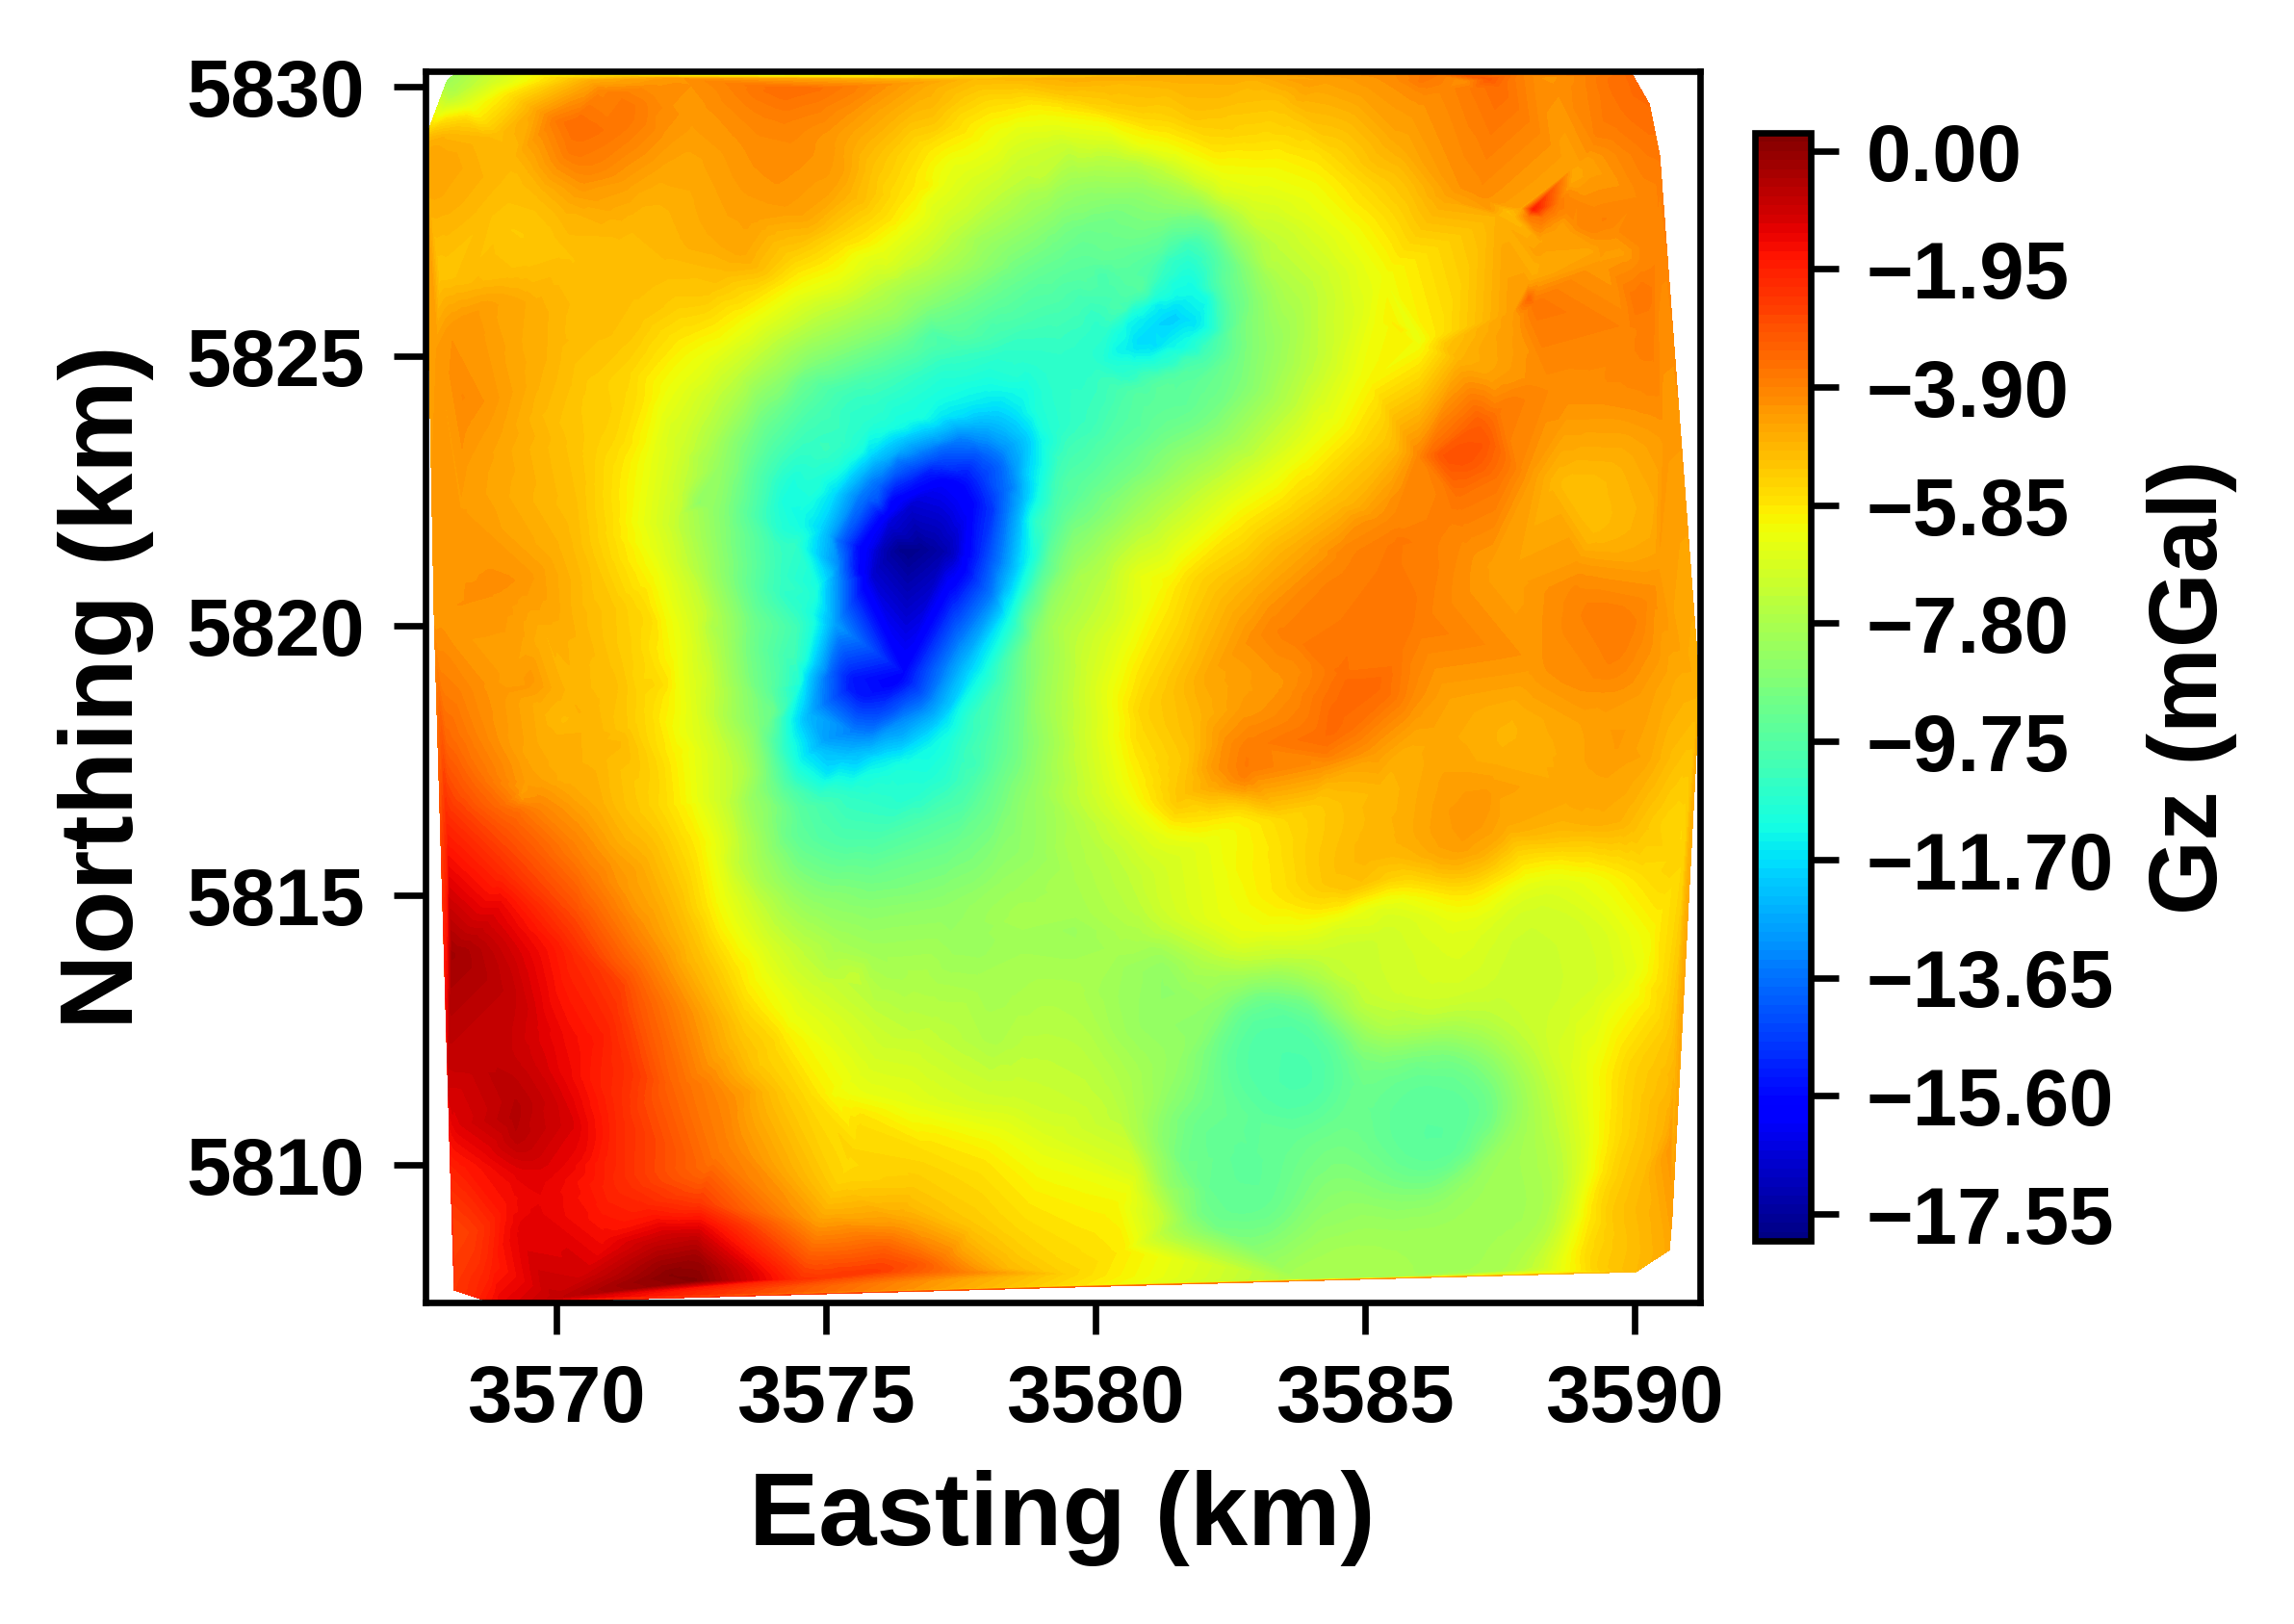

In [6]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation

# Load [x, y, Gz] — x and y are already in km
data = sio.loadmat("xyz_gz.mat")["xyz_gz"]
x, y, gz = data[:,0], data[:,1], data[:,2]

# Triangulate irregularly spaced observations
tri = Triangulation(x, y)

# Plot Gz
fig, ax = plt.subplots(figsize=(4,3), dpi=600)
cf = ax.tricontourf(tri, gz, levels=150, cmap="jet")
ax.tricontour(tri, gz, levels=15, colors="none", linewidths=.45)

# Axes
ax.set(xlabel="Easting (km)", ylabel="Northing (km)",
       xlim=(x.min(),x.max()), ylim=(y.min(),y.max()))
ax.set_aspect("equal")
ax.tick_params(labelsize=10, direction="out", width=.8, length=4)
for t in ax.get_xticklabels()+ax.get_yticklabels(): t.set_fontweight("bold")

# Colorbar
cb = fig.colorbar(cf, ax=ax, pad=.035, shrink=.90)
cb.set_label("Gz (mGal)", fontsize=12, fontweight="bold")
cb.ax.tick_params(labelsize=10)

# Save
fig.tight_layout()
fig.savefig("Gz_plot.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()

In [1]:
# CELL 1 — INVERSION ONLY
import numpy as np
from scipy.io import loadmat
from scipy.interpolate import griddata
from scipy.sparse import lil_matrix, diags, vstack, csr_matrix
import time, warnings
warnings.filterwarnings("ignore")

# ─── path to data ────────────────────────────────────────────────────────────
MAT_PATH = "/home/rahul/MTP/INVERSION/ACGLSR_Method/Real_data_Inversion/Real_gz_Inv/xyz_gz.mat"   
# ─────────────────────────────────────────────────────────────────────────────
G = 6.67e-11   # m^3 kg^-1 s^-2
# ══════════════════════════════════════════════════════════════════════════════
# 1  PRISM FORWARD MODELLING  (Nagy et al. gz kernel only)
# ══════════════════════════════════════════════════════════════════════════════

_SIGNS = np.array([(-1)**(i+j+k) for i in range(2)
                                   for j in range(2)
                                   for k in range(2)], dtype=float)

def _slog(v):       return np.log(np.where(np.abs(v) > 1e-30, np.abs(v), 1e-30))
def _satan(y, x):   return np.arctan2(y, np.where(np.abs(x) > 1e-30, x, 1e-30))
def _r(dx, dy, dz): return np.sqrt(dx**2 + dy**2 + dz**2)

def _kernel_gz(dx, dy, dz):
    return (dx*_slog(dy+_r(dx,dy,dz)) + dy*_slog(dx+_r(dx,dy,dz))
            - dz*_satan(dx*dy, dz*_r(dx,dy,dz)))

def build_A_gz(obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2):
    
    N, M = len(obs_x), len(px1)
    A = np.zeros((N, M))
    for s_idx in range(8):
        i = s_idx // 4
        j = (s_idx // 2) % 2
        k = s_idx % 2
        cx = [px1, px2]; cy = [py1, py2]; cz = [pz1, pz2]
        dx = cx[i] - obs_x[:, None]
        dy = cy[j] - obs_y[:, None]
        dz = cz[k] - obs_z[:, None]
        A += _SIGNS[s_idx] * _kernel_gz(dx, dy, dz)
    return G * A * 1e5   # [mGal per kg/m^3]


# ══════════════════════════════════════════════════════════════════════════════
# 2  MODEL WEIGHTING OPERATORS  ( smallness + smoothness)
# ══════════════════════════════════════════════════════════════════════════════

def build_Ss(M, weights=None):
    """Ss: diagonal cell-weight matrix for the smallness term."""
    if weights is None:
        return np.ones(M)          # Ss = I
    return np.asarray(weights)

def build_Ds(dx, dy, dz, M):
    """Ds: diagonal matrix, sqrt(cell volume) repeated M times."""
    return np.full(M, np.sqrt(dx * dy * dz))

# ── FIX (Bug #1): Sx/Sy/Sz are now PURE volume/shape weights — sqrt of
#    the interface cell volume, exactly analogous to Ds for smallness.
#    They carry NO depth dependence. Depth-weighting is applied exactly
#    once per term, via Zdiag, inside build_Wm_full().
def build_Sx(dx, dy, dz, nx, ny, nz):
    """Sx: interface volume-weight along x. Length nz*ny*(nx-1)."""
    n_out = nz * ny * (nx - 1)
    return np.full(n_out, np.sqrt(dx * dy * dz))

def build_Sy(dx, dy, dz, nx, ny, nz):
    """Sy: interface volume-weight along y. Length nz*(ny-1)*nx."""
    n_out = nz * (ny - 1) * nx
    return np.full(n_out, np.sqrt(dx * dy * dz))

def build_Sz(dx, dy, dz, nx, ny, nz):
    """Sz: interface volume-weight along z. Length (nz-1)*ny*nx."""
    n_out = (nz - 1) * ny * nx
    return np.full(n_out, np.sqrt(dx * dy * dz))

def build_Dx(nx, ny, nz):
    """First-difference operator along x. Output shape (nz*ny*(nx-1), M)."""
    n_out = nz * ny * (nx - 1)
    n_in  = nz * ny * nx
    Dx = lil_matrix((n_out, n_in))
    row = 0
    for iz in range(nz):
        for iy in range(ny):
            for ix in range(nx - 1):
                idx_here = iz*ny*nx + iy*nx + ix
                idx_next = iz*ny*nx + iy*nx + (ix + 1)
                Dx[row, idx_next] =  1.0
                Dx[row, idx_here] = -1.0
                row += 1
    return Dx.tocsr()

def build_Dy(nx, ny, nz):
    """First-difference operator along y. Output shape (nz*(ny-1)*nx, M)."""
    n_out = nz * (ny - 1) * nx
    n_in  = nz * ny * nx
    Dy = lil_matrix((n_out, n_in))
    row = 0
    for iz in range(nz):
        for iy in range(ny - 1):
            for ix in range(nx):
                idx_here = iz*ny*nx + iy*nx + ix
                idx_next = iz*ny*nx + (iy + 1)*nx + ix
                Dy[row, idx_next] =  1.0
                Dy[row, idx_here] = -1.0
                row += 1
    return Dy.tocsr()

def build_Dz(nx, ny, nz):
    """First-difference operator along z. Output shape ((nz-1)*ny*nx, M)."""
    n_out = (nz - 1) * ny * nx
    n_in  = nz * ny * nx
    Dz = lil_matrix((n_out, n_in))
    row = 0
    for iz in range(nz - 1):
        for iy in range(ny):
            for ix in range(nx):
                idx_here = iz*ny*nx + iy*nx + ix
                idx_next = (iz + 1)*ny*nx + iy*nx + ix
                Dz[row, idx_next] =  1.0
                Dz[row, idx_here] = -1.0
                row += 1
    return Dz.tocsr()

def build_all_weight_operators(pz_c, dx, dy, dz, nx, ny, nz,
                                z0=800.0, beta=2,
                                alpha_s=1.0, alpha_x=1.0,
                                alpha_y=1.0, alpha_z=1.0):
    """Construct every S, D matrix + depth-weight Z, return as a dict."""
    w = 1.0 / (z0 + pz_c) ** (beta / 2.0)     # Z — Eq.(19), shared by all 4 terms
    M = nx * ny * nz

    Ss = build_Ss(M)
    Ds = build_Ds(dx, dy, dz, M)

    # FIX (Bug #1): pure volume weights, no depth dependence
    Sx = build_Sx(dx, dy, dz, nx, ny, nz)
    Sy = build_Sy(dx, dy, dz, nx, ny, nz)
    Sz = build_Sz(dx, dy, dz, nx, ny, nz)

    Dx = build_Dx(nx, ny, nz)
    Dy = build_Dy(nx, ny, nz)
    Dz = build_Dz(nx, ny, nz)

    return {
        'w': w, 'Ss': Ss, 'Ds': Ds,
        'Sx': Sx, 'Sy': Sy, 'Sz': Sz,
        'Dx': Dx, 'Dy': Dy, 'Dz': Dz,
        'alpha_s': alpha_s, 'alpha_x': alpha_x,
        'alpha_y': alpha_y, 'alpha_z': alpha_z,
    }

def build_Wm_full(ops):
    """
    Assemble the FULL model weighting operator (Eqs. 16-18):

        Wm = [ alpha_s * Ss*Ds*Z ]      (smallness,    M            rows)
             [ alpha_x * Sx*Dx*Z ]      (x-smoothness, nz*ny*(nx-1) rows)
             [ alpha_y * Sy*Dy*Z ]      (y-smoothness, nz*(ny-1)*nx rows)
             [ alpha_z * Sz*Dz*Z ]      (z-smoothness, (nz-1)*ny*nx rows)

    Z (the depth weight `w`) now enters every term EXACTLY ONCE, via
    Zdiag on the right — Si carries no depth dependence (Bug #1 fix).
    Returned as a sparse CSR matrix of shape (M + n_x + n_y + n_z, M).
    """
    w = ops['w']
    M = len(w)
    Zdiag = diags(w)

    Ws = ops['alpha_s'] * diags(ops['Ss'] * ops['Ds'] * ops['w'])       # (M, M)
    Wx = ops['alpha_x'] * (diags(ops['Sx']) @ ops['Dx'] @ Zdiag)        # (n_x, M)
    Wy = ops['alpha_y'] * (diags(ops['Sy']) @ ops['Dy'] @ Zdiag)        # (n_y, M)
    Wz = ops['alpha_z'] * (diags(ops['Sz']) @ ops['Dz'] @ Zdiag)        # (n_z, M)

    Wm = vstack([Ws, Wx, Wy, Wz], format="csr")
    return Wm


# ══════════════════════════════════════════════════════════════════════════════
# 3  ACGLSR — general sparse Wm, relative mu2 floor,
#             CG restarted every iteration (Bugs #2, #3 fixed)
# ══════════════════════════════════════════════════════════════════════════════

def _spectral_norm(matvec, M, iters=20, seed=0):
    """
    Power-iteration estimate of the spectral norm (largest eigenvalue,
    both operators here are PSD) of a linear operator given only as a
    matvec callable. Used to calibrate mu2 against the ACTUAL operator
    norms of A^T Wd^T Wd A and Wm^T Wm, rather than an assumed trial
    perturbation size (see Bug #4 below).
    """
    rng = np.random.default_rng(seed)
    v = rng.normal(size=M)
    v /= np.linalg.norm(v) + 1e-30
    lam = 0.0
    for _ in range(iters):
        v_new = matvec(v)
        norm = np.linalg.norm(v_new)
        if norm < 1e-30:
            return 0.0
        v = v_new / norm
        lam = norm
    return lam


def acglsr(A, d_obs, wd, Wm, m0=None, Nmax=100, tol=1e-8,
           delta=0.75, m_low=-np.inf, m_high=np.inf,
           mu2_init_factor=1e3, mu2_floor_factor=1e-1,
           restart_every_iter=True, verbose=True):
    
    N, M = A.shape
    if m0 is None:
        m0 = np.zeros(M)

    Aw = wd[:, None] * A                  # Wd @ A   (Wd = diag(wd))
    dw = wd * (d_obs - A @ m0)            # Wd @ (dobs - A m0)

    def Qv(v, mu2):
        """(A^T Wd^T Wd A + mu2 * Wm^T Wm) @ v"""
        AtA_v  = Aw.T @ (Aw @ v)
        Wmv    = Wm @ v
        WtWm_v = Wm.T @ Wmv
        return AtA_v + mu2 * WtWm_v

    b = Aw.T @ dw                                 # target vector (RHS)

    # FIX (Bug #4): operator-norm-based mu2 calibration
    lam_AtA = _spectral_norm(lambda v: Aw.T @ (Aw @ v), M)
    lam_WtW = _spectral_norm(lambda v: Wm.T @ (Wm @ v), M)
    ratio   = lam_AtA / (lam_WtW + 1e-30)
    mu2_init  = mu2_init_factor  * ratio
    mu2_floor = mu2_floor_factor * ratio
    mu2       = mu2_init

    if verbose:
        print(f"  lambda_max(AtA)={lam_AtA:.4e}  lambda_max(WtW)={lam_WtW:.4e}  "
              f"ratio={ratio:.4e}")
        print(f"  Initial mu^2 = {mu2:.4e}  (floor = {mu2_floor:.4e})")

    dm_k = np.zeros(M)                            # delta_m = m - m0
    fk   = Qv(dm_k, mu2) - b                       # residual of normal eqn
    dk   = fk.copy()
    Qdk  = Qv(dk, mu2)
    tk   = np.dot(dk, fk) / (np.dot(dk, Qdk) + 1e-30)

    m_k   = np.clip(dm_k + m0, m_low, m_high)
    resid = wd * (A @ m_k - d_obs)
    phi_d = float(np.dot(resid, resid))
    phi_hist = [phi_d]
    m_best   = m_k.copy()

    if verbose:
        print(f"\n  {'Iter':>5}  {'phi_d':>14}  {'mu2':>12}  {'||m||_inf':>10}")
        print("  " + "-" * 52)
        print(f"  {'0':>5}  {phi_d:>14.6e}  {mu2:>12.4e}  "
              f"{np.abs(m_k).max():>10.4f}")

    for k in range(Nmax):
        dm_k   = dm_k - tk * dk
        m_k    = np.clip(dm_k + m0, m_low, m_high)
        dm_k   = m_k - m0                          # re-sync after clipping
        m_best = m_k.copy()

        resid  = wd * (A @ m_k - d_obs)
        phi_d  = float(np.dot(resid, resid))
        phi_hist.append(phi_d)

        if verbose:
            print(f"  {k+1:>5}  {phi_d:>14.6e}  {mu2:>12.4e}  "
                  f"{np.abs(m_k).max():>10.4f}")

        if phi_d < tol:
            if verbose:
                print(f"\n  Converged at iteration {k+1}")
            break

        mu2 = max(delta * mu2, mu2_floor)          

        fk_new = Qv(dm_k, mu2) - b

        if restart_every_iter:
            
            dk_new = fk_new.copy()
        else:
            beta_k = np.dot(fk_new, fk_new) / (np.dot(fk, fk) + 1e-30)
            dk_new = fk_new + beta_k * dk

        Qdk    = Qv(dk_new, mu2)
        tk     = np.dot(dk_new, fk_new) / (np.dot(dk_new, Qdk) + 1e-30)

        fk = fk_new
        dk = dk_new

    return m_best, phi_hist


t0 = time.time()
print("=" * 70)
print("  ACGLSR — Real Bouguer gz Inversion  ")
print("  Wm = smallness + x/y/z smoothness  ]")
print("=" * 70)

# ── 1. Load & preprocess data ─────────────────────────────────────────
print("\n  Loading data ...")
mat  = loadmat(MAT_PATH)
raw  = mat["xyz_gz"]                       # (8188, 3)
x_km = raw[:, 0]
y_km = raw[:, 1]
gz   = raw[:, 2]

x0, y0   = x_km.min(), y_km.min()
x_m      = (x_km - x0) * 1000.0
y_m      = (y_km - y0) * 1000.0

# Original absolute coordinates for plotting/printing
x_abs_km = x_km.copy()
y_abs_km = y_km.copy()

print("\n  Original uploaded coordinates:")
print(f"  x : {x_abs_km.min():.3f} to {x_abs_km.max():.3f} km")
print(f"  y : {y_abs_km.min():.3f} to {y_abs_km.max():.3f} km")
print(f"  Gz: {gz.min():.3f} to {gz.max():.3f} mGal")

print("\n  Local inversion coordinates:")
print(f"  x : {x_m.min():.2f} to {x_m.max():.2f} m")
print(f"  y : {y_m.min():.2f} to {y_m.max():.2f} m")

span_x   = x_m.max()
span_y   = y_m.max()

print(f"  \n\nSurvey extent : {span_x/1000:.2f} km (EW)  x  {span_y/1000:.2f} km (NS)")
print(f"  gz range      : {gz.min():.4f}  to  {gz.max():.4f} mGal")

# ── 2. Regular observation grid ────────────────────────────────────────
nx_obs, ny_obs = 40, 40
xe_obs = np.linspace(0, span_x, nx_obs + 1)
ye_obs = np.linspace(0, span_y, ny_obs + 1)
xe_c   = 0.5 * (xe_obs[:-1] + xe_obs[1:])
ye_c   = 0.5 * (ye_obs[:-1] + ye_obs[1:])
Xo, Yo = np.meshgrid(xe_c, ye_c, indexing='xy')

# Absolute coordinates of observation-grid cells
Xo_abs_km = Xo/1000 + x0
Yo_abs_km = Yo/1000 + y0

gz_grid = griddata((x_m, y_m), gz, (Xo, Yo), method="linear")
if np.isnan(gz_grid).any():
    gz_nn = griddata((x_m, y_m), gz, (Xo, Yo), method="nearest")
    mask  = np.isnan(gz_grid)
    gz_grid[mask] = gz_nn[mask]
    print(f"  Filled {mask.sum()} NaN cells with nearest-neighbour values")

obs_x  = Xo.ravel()
obs_y  = Yo.ravel()
obs_z  = np.zeros(len(obs_x))
d_obs  = gz_grid.ravel()
N_obs  = len(d_obs)
print(f"  \n\nInterpolated gz  : min={d_obs.min():.4f}  max={d_obs.max():.4f} mGal")
print(f"  N_obs            : {N_obs}  ({nx_obs}x{ny_obs} grid)")

# ── 3. Prism grid ───────────────────────────────────────────────────────
nx, ny, nz = 40, 40, 25
dx   = span_x / nx
dy_p = span_y / ny
dz   = 240

xe  = np.linspace(0, span_x, nx + 1)
ye  = np.linspace(0, span_y, ny + 1)
ze  = np.linspace(0, nz * dz, nz + 1)

iz_g, iy_g, ix_g = np.meshgrid(np.arange(nz), np.arange(ny),
                                np.arange(nx), indexing='ij')
ix_g = ix_g.ravel(); iy_g = iy_g.ravel(); iz_g = iz_g.ravel()
px1 = xe[ix_g];  px2 = xe[ix_g + 1]
py1 = ye[iy_g];  py2 = ye[iy_g + 1]
pz1 = ze[iz_g];  pz2 = ze[iz_g + 1]
pz_c = 0.5 * (pz1 + pz2)
M    = len(px1)

xe_c_p = 0.5 * (xe[:-1] + xe[1:])
ye_c_p = 0.5 * (ye[:-1] + ye[1:])
ze_c   = 0.5 * (ze[:-1] + ze[1:])
sh     = (nz, ny, nx)

print(f"  Prism grid       : {nx}x{ny}x{nz} = {M} cells")
print(f"  Cell size        : {dx:.0f} m x {dy_p:.0f} m x {dz:.0f} m")
print(f"  Depth range      : 0 - {nz*dz/1000:.1f} km")

# ── 4. Design matrix ──────────────────────────────────────────────────
print("\n  Building gz design matrix A ...")
A = build_A_gz(obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2)
print(f"  A : {A.shape[0]} x {A.shape[1]}")
print(f"  A max abs : {np.abs(A).max():.4e}")

d_zero = A @ np.zeros(M)
assert np.allclose(d_zero, 0), "A @ 0 != 0 -- kernel bug"

# ── 5. Data weights ───────────────────────────────────────────────────
sigma_gz = 0.5
wd = np.full(N_obs, 1.0 / sigma_gz)
print(f"\n  Data noise sigma : {sigma_gz} mGal   (wd = {wd[0]:.1f})")

# ── 6. Full model weighting operator: smallness + smoothness ──────────
#  beta=2 for gz-only inversion, z0 = one layer thickness 
#  alpha_s, alpha_x, alpha_y, alpha_z control the relative strength of
#  the smallness term vs. the three smoothness terms 
ops = build_all_weight_operators(
    pz_c, dx, dy_p, dz, nx, ny, nz,
    z0=dz/2, beta=2,
    alpha_s=1.0, alpha_x=0.1, alpha_y=0.1, alpha_z=0.1
)
Wm = build_Wm_full(ops)
print(f"  Wm shape         : {Wm.shape}  "
      f"(M={M} smallness rows + "
      f"{ops['Dx'].shape[0]} x-smoothness + "
      f"{ops['Dy'].shape[0]} y-smoothness + "
      f"{ops['Dz'].shape[0]} z-smoothness)")
print(f"  Wm nnz           : {Wm.nnz}")

# ── 7. ACGLSR ─────────────────────────────────────────────────────────
print("\n  Running ACGLSR ...\n")
m_pred, phi_hist = acglsr(
    A, d_obs, wd, Wm,
    m0     = np.zeros(M),
    Nmax   = 500,
    tol    = 1e-12,
    delta  = 0.75,
    m_low  = -600.0,
    m_high =  600.0,
    mu2_init_factor  = 1e3,
    mu2_floor_factor = 1e-1,
    restart_every_iter = True,
    verbose= True
)

d_pred  = A @ m_pred
elapsed = time.time() - t0
rms_fit = np.sqrt(np.mean((d_pred - d_obs)**2))
print(f"\n  Data RMS misfit  : {rms_fit:.4f} mGal")
print(f"  Max |predicted|  : {np.abs(m_pred).max():.2f} kg/m^3")
print(f"  Elapsed          : {elapsed:.1f} s")

mp3 = m_pred.reshape(sh)

print("\n  Inversion cell completed.")
print("\n  Depth-layer summary:")
print(f"  {'Depth (m)':>12}  {'mean|rho| (kg/m3)':>18}  {'max|rho| (kg/m3)':>16}")
for iz in range(nz):
    layer = np.abs(mp3[iz])
    print(f"  {ze_c[iz]:>12.0f}  {layer.mean():>18.3f}  {layer.max():>16.3f}")

  ACGLSR — Real Bouguer gz Inversion  (Chen et al. 2024)
  Wm = smallness + x/y/z smoothness  (Eqs. 16-18)  [v2, 3 bugs fixed]

  Loading data ...

  Original uploaded coordinates:
  x : 3567.560 to 3591.210 km
  y : 5807.440 to 5830.290 km
  Gz: -17.860 to 0.190 mGal

  Local inversion coordinates:
  x : 0.00 to 23650.00 m
  y : 0.00 to 22850.00 m
  

Survey extent : 23.65 km (EW)  x  22.85 km (NS)
  gz range      : -17.8600  to  0.1900 mGal
  Filled 59 NaN cells with nearest-neighbour values
  

Interpolated gz  : min=-17.7183  max=-0.2418 mGal
  N_obs            : 1600  (40x40 grid)
  Prism grid       : 40x40x25 = 40000 cells
  Cell size        : 591 m x 571 m x 240 m
  Depth range      : 0 - 6.0 km

  Building gz design matrix A ...
  A : 1600 x 40000
  A max abs : 6.7348e-03

  Data noise sigma : 0.5 mGal   (wd = 2.0)
  Wm shape         : (156400, 40000)  (M=40000 smallness rows + 39000 x-smoothness + 39000 y-smoothness + 38400 z-smoothness)
  Wm nnz           : 272800

  Running 

In [2]:
# =============================================================================
# CONDITION NUMBER OF THE RAW GRAVITY KERNEL
# =============================================================================
print("\n  Calculating condition number of A ...")

# Singular values of A
singular_values = np.linalg.svd(
    A,
    compute_uv=False
)
sigma_max = singular_values[0]
sigma_min = singular_values[-1]

condition_number_A = sigma_max / sigma_min

print("\n" + "=" * 65)
print("  CONDITION NUMBER — RAW gz KERNEL")
print("=" * 65)

print(f"  Kernel shape             : {A.shape}")
print(f"  Number of observations   : {A.shape[0]}")
print(f"  Number of model cells    : {A.shape[1]}")
print(f"  Largest singular value   : {sigma_max:.6e}")
print(f"  Smallest singular value  : {sigma_min:.6e}")
print(f"  Condition number κ(A)    : {condition_number_A:.6e}")

if condition_number_A < 1e2:
    print("  Interpretation            : Well conditioned")
elif condition_number_A < 1e4:
    print("  Interpretation            : Moderately ill-conditioned")
elif condition_number_A < 1e6:
    print("  Interpretation            : Strongly ill-conditioned")
elif condition_number_A < 1e10:
    print("  Interpretation            : Severely ill-conditioned")
else:
    print("  Interpretation            : Extremely ill-conditioned")

print("=" * 65)



# ── Raw observed gravity data ───────────────────────────────────────────
print(f"\nRaw observed Gz data (N={len(gz)}):")
print(gz)
print(f"  Maximum : {gz.max():.6f} mGal")
print(f"  Minimum : {gz.min():.6f} mGal")
print(f"  Mean    : {gz.mean():.6f} mGal")
print(f"  Std     : {gz.std():.6f} mGal")

# ── Gridded/interpolated gravity data ──────────────────────────────────
print(f"\nGridded/interpolated Observed Gz data ({nx_obs}×{ny_obs}, N={len(d_obs)}):")
print(d_obs)
print(f"  Maximum : {d_obs.max():.60f} mGal")
print(f"  Minimum : {d_obs.min():.60f} mGal")
print(f"  Mean    : {d_obs.mean():.6f} mGal")
print(f"  Std     : {d_obs.std():.6f} mGal")


  Calculating condition number of A ...

  CONDITION NUMBER — RAW gz KERNEL
  Kernel shape             : (1600, 40000)
  Number of observations   : 1600
  Number of model cells    : 40000
  Largest singular value   : 3.513229e-02
  Smallest singular value  : 5.813375e-03
  Condition number κ(A)    : 6.043356e+00
  Interpretation            : Well conditioned

Raw observed Gz data (N=8188):
[-5.26 -6.33 -7.39 ... -6.04 -5.7  -5.81]
  Maximum : 0.190000 mGal
  Minimum : -17.860000 mGal
  Mean    : -7.142732 mGal
  Std     : 2.714300 mGal

Gridded/interpolated Observed Gz data (40×40, N=1600):
[-2.42       -2.17390513 -1.52341286 ... -3.5050813  -3.44
 -3.44      ]
  Maximum : -0.241840396445779926004604476474924013018608093261718750000000 mGal
  Minimum : -17.718318965517120489039371022954583168029785156250000000000000 mGal
  Mean    : -6.231464 mGal
  Std     : 2.790648 mGal



GRAVITY STATISTICS

Observed:
  Maximum = -0.241840
  Minimum = -17.718319
  Mean = -6.231464

Predicted:
  Maximum = -0.480661
  Minimum = -17.264195
  Mean = -6.220023

Residual:
  Maximum = 0.600091
  Minimum = -1.766902
  Mean = -0.011441

RMS between observed and predicted Gz = 0.133110 mGal


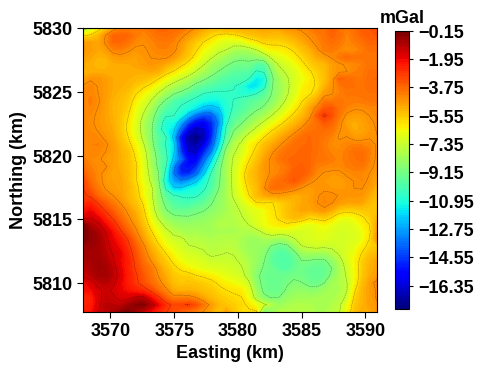

Saved: Fig01_Observed_Gz.png


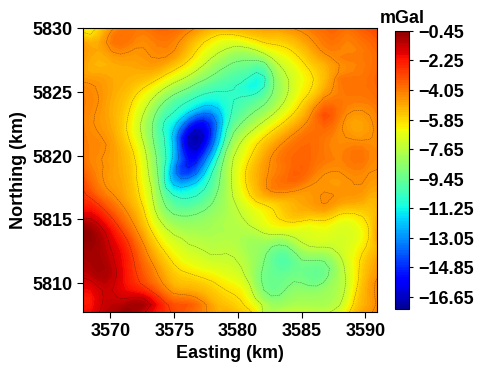

Saved: Fig02_Predicted_Gz.png


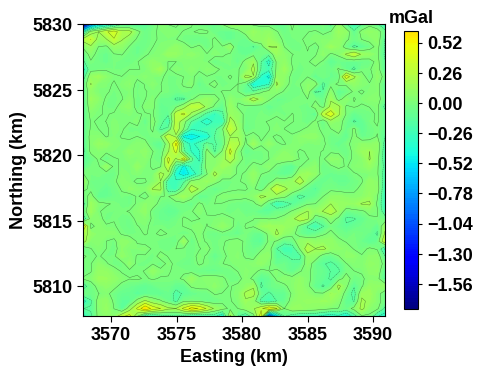

Saved: Fig03_Residual_Gz.png


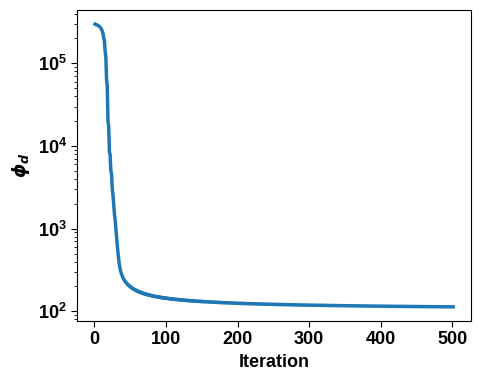

Saved: Fig04_Convergence.png
Convergence data saved: /home/rahul/MTP/INVERSION/ACGLSR_Method/Real_data_Inversion/Combined_Convergence_all_components/r_gz_Conver_Data.xlsx

EW profile saved: EW_Gz_Gravity_Profile.xlsx
EW profile Northing: 5821.435625 km


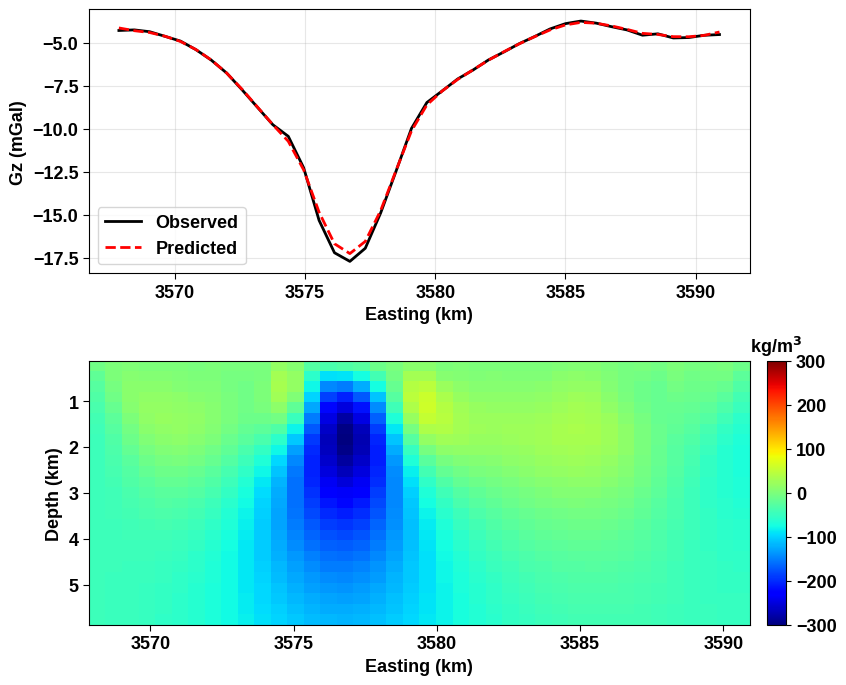

Saved: EW_profile_density_section.png

NS profile saved: NS_Gz_Gravity_Profile.xlsx
NS profile Easting: 3576.724375 km


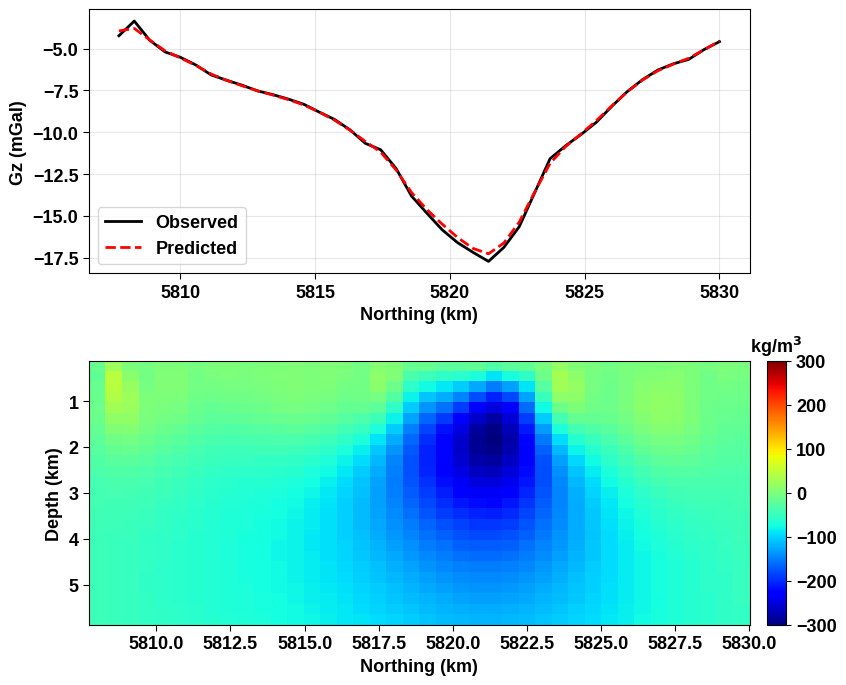

Saved: NS_profile_density_section.png


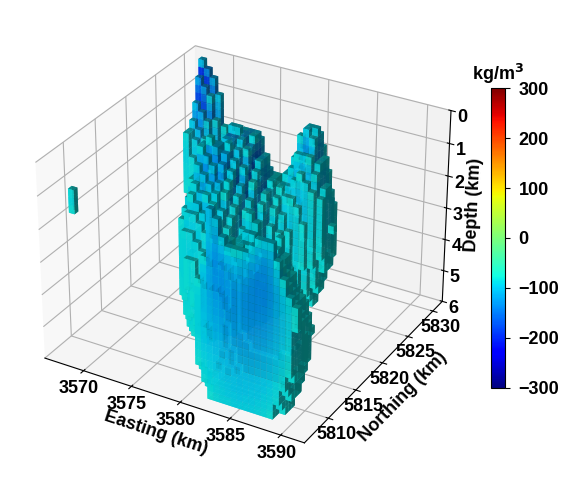

Saved: real_gz_3d_model.png


EW Density section along maximum negative density contrast at y(Northing) = 5821.44 km


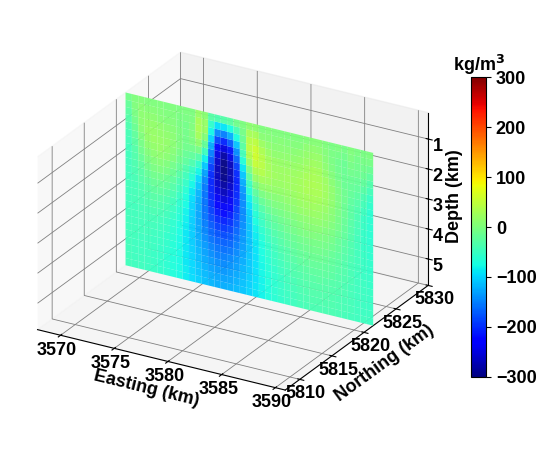

Saved: EW_density_section_3D.png


NS Density section along maximum negative density contrast at x(Easting) = 3576.72 km


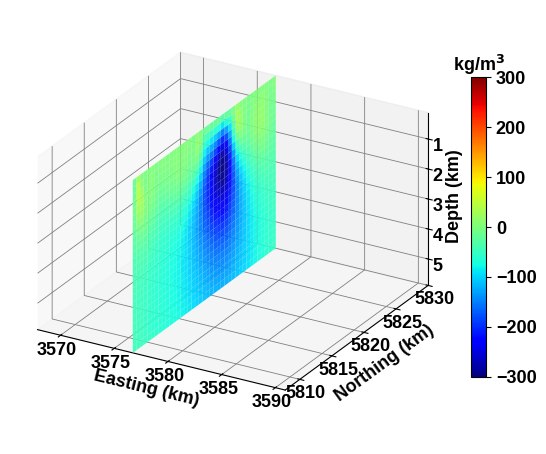

Saved: NS_density_section_3D.png


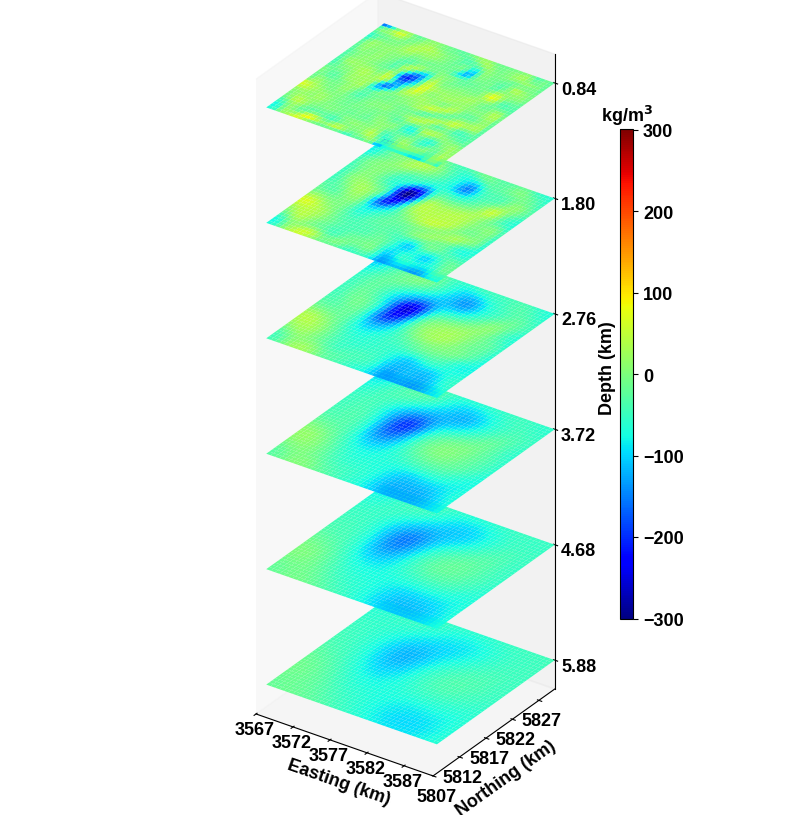


  Depth-layer summary:
     Depth (m)   mean|rho| (kg/m3)  max|rho| (kg/m3)
           120               5.139           105.282
           360              11.385           190.838
           600              16.578           224.645
           840              21.248           240.982
          1080              25.925           249.011
          1320              30.906           280.629
          1560              36.112           297.232
          1800              41.255           300.624
          2040              45.897           294.586
          2280              49.890           282.816
          2520              53.266           268.107
          2760              56.085           252.306
          3000              58.305           236.530
          3240              60.012           221.402
          3480              61.333           207.233
          3720              62.365           194.149
          3960              63.164           182.165
          4200        

In [8]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from PIL import Image, ImageChops
# ---------------------------------------------------------------------
# 1. PUBLICATION SETTINGS
# ---------------------------------------------------------------------
BG=AX="white"; TC="black"; FS=13; DPI=600; LW=.8
mpl.rcParams.update({
    "font.family":"Liberation Sans","font.size":FS,
    "axes.labelsize":FS,"xtick.labelsize":FS,"ytick.labelsize":FS,
    "legend.fontsize":FS,"figure.facecolor":BG,"axes.facecolor":AX,
    "savefig.dpi":DPI,"savefig.facecolor":BG,"axes.edgecolor":TC,
    "axes.linewidth":LW,"xtick.color":TC,"ytick.color":TC,
    "text.color":TC,"axes.labelcolor":TC,"ps.fonttype":42,
    "font.weight":"bold","axes.labelweight":"bold"
})
# ---------------------------------------------------------------------
# 2. COMMON PLOTTING FUNCTIONS
# ---------------------------------------------------------------------
def style_2d(ax,xlabel="",ylabel=""):
    ax.set_facecolor(AX)
    ax.tick_params(colors=TC,labelsize=FS,direction="out",width=LW,length=4)
    ax.set_xlabel(xlabel,color=TC,fontsize=FS,fontweight="bold")
    ax.set_ylabel(ylabel,color=TC,fontsize=FS,fontweight="bold")
    for s in ax.spines.values(): s.set_edgecolor(TC); s.set_linewidth(LW)
    for t in ax.get_xticklabels()+ax.get_yticklabels(): t.set_fontweight("bold")

def add_cbar(cf,ax,fig,title,shrink=.90,pad=.05):
    cb=fig.colorbar(cf,ax=ax,shrink=shrink,pad=pad)
    cb.ax.set_title(title,fontsize=FS,fontweight="bold",color=TC,pad=6)
    cb.ax.tick_params(labelsize=FS,colors=TC,direction="out",width=LW,length=3)
    plt.setp(cb.ax.get_yticklabels(),fontweight="bold")
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(LW)
    return cb

def save_fig(fig,filename,tight=True):
    fig.tight_layout()
    kw={"dpi":DPI,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
# ---------------------------------------------------------------------
# 3. OBSERVATION GRID AND Gz DATA
# ---------------------------------------------------------------------
ng=int(np.sqrt(N_obs))
if ng*ng!=N_obs: raise ValueError(f"N_obs={N_obs} is not a square grid.")
X,Y=obs_x.reshape(ng,ng),obs_y.reshape(ng,ng)
# Absolute observation-grid coordinates for plotting
X_abs_km = X/1000 + x0
Y_abs_km = Y/1000 + y0
Zobs,Zpred=d_obs.reshape(ng,ng),d_pred.reshape(ng,ng); Zres=Zobs-Zpred
vmin=min(np.nanmin(Zobs),np.nanmin(Zpred)); vmax=max(np.nanmax(Zobs),np.nanmax(Zpred))
rmax=np.nanmax(np.abs(Zres))

# ---------------------------------------------------------------------
# 5. GRAVITY STATISTICS
# ---------------------------------------------------------------------
def gravity_statistics(obs,pred,res):
    rms=np.sqrt(np.nanmean(res**2))
    print("\n"+"="*70+"\nGRAVITY STATISTICS\n"+"="*70)
    for name,d in [("Observed",obs),("Predicted",pred),("Residual",res)]:
        print(f"\n{name}:\n  Maximum = {np.nanmax(d):.6f}\n  Minimum = {np.nanmin(d):.6f}\n  Mean = {np.nanmean(d):.6f}")
    print(f"\nRMS between observed and predicted Gz = {rms:.6f} mGal\n"+"="*70)
    return rms
rms=gravity_statistics(Zobs,Zpred,Zres)

# ---------------------------------------------------------------------
# 4. Gz MAP
# ---------------------------------------------------------------------
def plot_gz(data,filename,vmin,vmax):
    fig,ax=plt.subplots(figsize=(5,4))
    cf=ax.contourf(X_abs_km,Y_abs_km,data,levels=150,cmap="jet",vmin=vmin,vmax=vmax)
    ax.contour(X_abs_km,Y_abs_km,data,levels=15,colors="k",linewidths=.3,alpha=.5)
    style_2d(ax,"Easting (km)","Northing (km)"); ax.set_aspect("equal")
    add_cbar(cf,ax,fig,"mGal"); save_fig(fig,filename)
    
plot_gz(Zobs,"Fig01_Observed_Gz.png",vmin,vmax)
plot_gz(Zpred,"Fig02_Predicted_Gz.png",vmin,vmax)
plot_gz(Zres,"Fig03_Residual_Gz.png",-rmax,rmax)

# ---------------------------------------------------------------------
# 6. CONVERGENCE CURVE + EXCEL
# ---------------------------------------------------------------------
def plot_convergence(phi,filename):
    fig,ax=plt.subplots(figsize=(5,4))
    ax.semilogy(np.arange(1,len(phi)+1),phi,lw=2.5)
    style_2d(ax,"Iteration",r"$\phi_d$"); save_fig(fig,filename)

def save_convergence_excel(phi,filename):
    pd.DataFrame({"Iteration":np.arange(1,len(phi)+1),"phi_d":phi}).to_excel(filename,index=False)
    print("Convergence data saved:",filename)

plot_convergence(phi_hist,"Fig04_Convergence.png")

convergence_file="/home/rahul/MTP/INVERSION/ACGLSR_Method/Real_data_Inversion/Combined_Convergence_all_components/r_gz_Conver_Data.xlsx"
save_convergence_excel(phi_hist,convergence_file)

# ---------------------------------------------------------------------
# 7. DENSITY SETTINGS
# ---------------------------------------------------------------------
abs_max=np.nanmax(np.abs(mp3)); clim=(-abs_max,abs_max)
cmap_m=plt.cm.jet; norm_m=mpl.colors.Normalize(*clim)
iz_min,iy_min,ix_min=np.unravel_index(np.nanargmin(mp3),mp3.shape)
x=np.asarray(xe_c_p)/1000; y=np.asarray(ye_c_p)/1000; z=np.asarray(ze_c)/1000

# ---------------------------------------------------------------------
# 8. EW/NS PROFILE + DENSITY SECTION
# ---------------------------------------------------------------------
def profile_section(obs,pred,rho,coord,mcoord,xlabel,filename):
    fig=plt.figure(figsize=(9,8))
    gs=GridSpec(2,2,figure=fig,width_ratios=[20,.6],height_ratios=[1,1],hspace=.33,wspace=.05)
    ax1=fig.add_subplot(gs[0,0])
    ax1.plot(coord,obs,"k-",lw=2,label="Observed"); ax1.plot(coord,pred,"r--",lw=2,label="Predicted")
    style_2d(ax1,xlabel,"Gz (mGal)"); ax1.grid(alpha=.3); ax1.legend(loc="best",prop={"weight":"bold"})
    fig.add_subplot(gs[0,1]).axis("off")
    ax2=fig.add_subplot(gs[1,0])
    im=ax2.imshow(rho,extent=[mcoord[0],mcoord[-1],z[-1],z[0]],origin="upper",aspect="auto",cmap=cmap_m,vmin=clim[0],vmax=clim[1])
    style_2d(ax2,xlabel,"Depth (km)")
    cax=fig.add_subplot(gs[1,1]); cb=fig.colorbar(im,cax=cax)
    cax.set_title(r"kg/m$^3$",color=TC,fontsize=FS,fontweight="bold",pad=6)
    cb.ax.tick_params(labelsize=FS,colors=TC); plt.setp(cb.ax.get_yticklabels(),fontweight="bold")
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(LW); save_fig(fig,filename)


iy_obs=np.argmin(np.abs(ye_c-ye_c_p[iy_min]))
ew_coordinate = xe_c/1000 + x0
ew_obs = Zobs[iy_obs]
ew_pred = Zpred[iy_obs]
ew_northing = ye_c[iy_obs]/1000 + y0
# Save EW gravity profile
pd.DataFrame({
    "Easting (km)": ew_coordinate,
    "Observed Gz (mGal)": ew_obs,
    "Predicted Gz (mGal)": ew_pred
}).to_excel(
    f"EW_Gz_Gravity_Profile_y{ew_northing:.3f}km.xlsx",
    index=False
)
print(f"\nEW profile saved: EW_Gz_Gravity_Profile.xlsx")
print(f"EW profile Northing: {ew_northing:.6f} km")
profile_section(Zobs[iy_obs],Zpred[iy_obs],mp3[:,iy_min,:],xe_c/1000+x0,xe_c_p/1000+x0,"Easting (km)","EW_profile_density_section.png")



ix_obs=np.argmin(np.abs(xe_c-xe_c_p[ix_min]))
ns_coordinate = ye_c/1000 + y0
ns_obs = Zobs[:,ix_obs]
ns_pred = Zpred[:,ix_obs]
ns_easting = xe_c[ix_obs]/1000 + x0
# Save NS gravity profile
pd.DataFrame({
    "Northing (km)": ns_coordinate,
    "Observed Gz (mGal)": ns_obs,
    "Predicted Gz (mGal)": ns_pred
}).to_excel(
    f"NS_Gz_Gravity_Profile_x{ns_easting:.3f}km.xlsx",
    index=False
)
print(f"\nNS profile saved: NS_Gz_Gravity_Profile.xlsx")
print(f"NS profile Easting: {ns_easting:.6f} km")
profile_section(Zobs[:,ix_obs],Zpred[:,ix_obs],mp3[:,:,ix_min],ye_c/1000+y0,ye_c_p/1000+y0,"Northing (km)","NS_profile_density_section.png")

# ---------------------------------------------------------------------
# 9. FULL 3-D DENSITY MODEL
# ---------------------------------------------------------------------
def plot_3d_model(filename):
    fig=plt.figure(figsize=(7,6)); ax=fig.add_subplot(111,projection="3d")
    X3,Y3,Z3=np.meshgrid(xe/1000+x0,ye/1000+y0,ze/1000,indexing="ij")
    v=np.nanmax(np.abs(mp3)); norm=mpl.colors.Normalize(-v,v); filled=np.abs(mp3)>.27*v
    fc=np.zeros((*mp3.shape,4)); fc[filled]=plt.cm.jet(norm(mp3[filled]))
    ax.voxels(X3,Y3,Z3,filled.transpose(2,1,0),facecolors=fc.transpose(2,1,0,3),edgecolor="none",alpha=.85)
    ax.set_xlabel("Easting (km)",fontsize=FS,fontweight="bold",color=TC,labelpad=-4.0)
    ax.set_ylabel("Northing (km)",fontsize=FS,fontweight="bold",color=TC,labelpad=-3.0)
    ax.set_zlabel("Depth (km)",fontsize=FS,fontweight="bold",color=TC,labelpad=-9.0)
    ax.set_zlim(ze[-1]/1000,0)
    for a in "xyz": ax.tick_params(axis=a,colors=TC,labelsize=FS,direction="out",width=.7,length=4,pad=-3.0)
    for t in ax.get_xticklabels()+ax.get_yticklabels()+ax.get_zticklabels(): t.set_fontweight("bold")
    sm=mpl.cm.ScalarMappable(cmap=plt.cm.jet,norm=norm); sm.set_array([])
    cax=fig.add_axes([.87,.25,.02,.50]); cb=fig.colorbar(sm,cax=cax)
    cax.set_title(r"kg/m$^3$",fontsize=FS,fontweight="bold",color=TC,pad=6)
    cb.ax.tick_params(labelsize=FS,colors=TC,pad=6); plt.setp(cb.ax.get_yticklabels(),fontweight="bold")
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(LW); save_fig(fig,filename)

plot_3d_model("real_gz_3d_model.png")

# ---------------------------------------------------------------------
# 10. INDIVIDUAL 3-D EW/NS SECTIONS
# ---------------------------------------------------------------------
def plot_3d_section(rho,X,Y,Z,filename):
    fig=plt.figure(figsize=(7,6)); ax=fig.add_subplot(111,projection="3d")
    fc=cmap_m(norm_m(rho)); fc[...,3]=.95
    ax.plot_surface(X,Y,Z,facecolors=fc,rstride=1,cstride=1,linewidth=0,edgecolor="none",shade=False)
    ax.set_xlabel("Easting (km)",fontsize=FS,fontweight="bold",labelpad=-4.0)
    ax.set_ylabel("Northing (km)",fontsize=FS,fontweight="bold",labelpad=-3.0)
    ax.set_zlabel("Depth (km)",fontsize=FS,fontweight="bold",labelpad=-10.0)
    ax.set_xlim(x.min()+x0,x.max()+x0); ax.set_ylim(y.min()+y0,y.max()+y0); ax.set_zlim(z.max(),z.min())
    ax.set_xticks(np.arange(np.ceil(x.min()+x0/5)*5,x.max()+x0+1,5)); ax.set_yticks(np.arange(np.ceil(y.min()+y0/5)*5,y.max()+y0+1,5))
    ax.set_zticks(np.arange(np.ceil(z.min()),np.floor(z.max())+1,1))
    for a in "xyz": ax.tick_params(axis=a,colors=TC,labelsize=FS,direction="out",width=.7,length=4,pad=-4.0)
    for t in ax.get_xticklabels()+ax.get_yticklabels()+ax.get_zticklabels(): t.set_fontweight("bold")
    ax.grid(True)
    for a in (ax.xaxis,ax.yaxis,ax.zaxis): a._axinfo["grid"].update(linewidth=.6,linestyle="-",color="gray",alpha=.5)
    ax.set_box_aspect((1.5,1.5,1)); ax.set_proj_type("ortho"); ax.view_init(elev=25,azim=-60)
    sm=mpl.cm.ScalarMappable(cmap=cmap_m,norm=norm_m); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=.65,pad=.05); cb.ax.set_title(r"kg/m$^3$",fontsize=FS,fontweight="bold",color=TC,pad=4)
    cb.ax.tick_params(labelsize=FS,colors=TC); save_fig(fig,filename)

rho=mp3[:,iy_min,:]; X,Z=np.meshgrid(x+x0,z); Y=np.full_like(X,y[iy_min]+y0)
print(f"\n\nEW Density section along maximum negative density contrast at y(Northing) = {(ye_c_p[iy_min]/1000+y0):.2f} km")
plot_3d_section(rho,X,Y,Z,"EW_density_section_3D.png")

rho=mp3[:,:,ix_min]; Y,Z=np.meshgrid(y+y0,z); X=np.full_like(Y,x[ix_min]+x0)
print(f"\n\nNS Density section along maximum negative density contrast at x(Easting) = {(xe_c_p[ix_min]/1000+x0):.2f} km")
plot_3d_section(rho,X,Y,Z,"NS_density_section_3D.png")

# ---------------------------------------------------------------------
# 11. HORIZONTAL SLICE DATA
# ---------------------------------------------------------------------
nz=mp3.shape[0]; slice_indices=np.linspace(3,nz-1,6,dtype=int)
depth_km=np.asarray(ze_c)/1000; slice_depths_km=depth_km[slice_indices]
xc_km=np.asarray(xe_c_p)/1000+x0; yc_km=np.asarray(ye_c_p)/1000+y0; Xc,Yc=np.meshgrid(xc_km,yc_km)
if Xc.shape!=mp3.shape[1:]: raise ValueError(f"Coordinate shape {Xc.shape} != model shape {mp3.shape[1:]}")

# ---------------------------------------------------------------------
# 12. SIX HORIZONTAL DENSITY SLICES
# ---------------------------------------------------------------------
def plot_horizontal_slices(filename):
    slice_gap=4.; slice_pos=np.arange(6)*slice_gap
    xmin,xmax=np.nanmin(xc_km),np.nanmax(xc_km); ymin,ymax=np.nanmin(yc_km),np.nanmax(yc_km)
    fig=plt.figure(figsize=(12,10)); ax=fig.add_subplot(111,projection="3d")
    for n,iz in enumerate(slice_indices):
        Zs=np.full_like(Xc,slice_pos[n],dtype=float); fc=cmap_m(norm_m(mp3[iz])); fc[...,3]=.90
        ax.plot_surface(Xc,Yc,Zs,facecolors=fc,rstride=1,cstride=1,linewidth=0,edgecolor="none",antialiased=True,shade=False,alpha=1)
    ax.set_xlim(xmin,xmax); ax.set_ylim(ymin,ymax); ax.set_zlim(slice_pos[-1]+1,-1)
    ax.set_xlabel("Easting (km)",fontsize=FS,color=TC,labelpad=-6.0,fontweight="bold")
    ax.set_ylabel("Northing (km)",fontsize=FS,color=TC,labelpad=-2.0,fontweight="bold")
    ax.set_zlabel("Depth (km)",fontsize=FS,color=TC,labelpad=30,fontweight="bold")
    xt=np.arange(np.floor(xmin),np.ceil(xmax)+1,5); yt=np.arange(np.floor(ymin),np.ceil(ymax)+1,5)
    ax.set_xticks(xt); ax.set_yticks(yt); ax.set_xticklabels([f"{q:.0f}" for q in xt]); ax.set_yticklabels([f"{q:.0f}" for q in yt])
    ax.set_zticks(slice_pos); ax.set_zticklabels([f"{q:.2f}" for q in slice_depths_km]); ax.minorticks_off(); ax.grid(False)
    for a in (ax.xaxis,ax.yaxis,ax.zaxis): a._axinfo["grid"]["linewidth"]=0
    ax.tick_params(axis="x",colors=TC,labelsize=FS,direction="out",width=.7,length=3,pad=-5.0)
    ax.tick_params(axis="y",colors=TC,labelsize=FS,direction="out",width=.7,length=3,pad=-3.0)
    ax.tick_params(axis="z",colors=TC,labelsize=FS,direction="out",width=.7,length=3,pad=15)
    for labels in (ax.get_xticklabels(),ax.get_yticklabels(),ax.get_zticklabels()): plt.setp(labels,fontweight="bold")
    ax.set_box_aspect((1.12,1.1,3.8)); ax.set_proj_type("ortho"); ax.view_init(elev=30,azim=-55)
    sm=mpl.cm.ScalarMappable(cmap=cmap_m,norm=norm_m); sm.set_array([])
    cax=fig.add_axes([.7,.27,.011,.49]) # left, bottom, width, height
    cb=fig.colorbar(sm,cax=cax)
    cax.set_title(r"kg/m$^3$",fontsize=FS,pad=6,color=TC,fontweight="bold"); cb.ax.tick_params(labelsize=FS,colors=TC)
    plt.setp(cb.ax.get_yticklabels(),fontweight="bold"); cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(LW)
    fig.savefig(filename,dpi=DPI,pad_inches=0,facecolor=fig.get_facecolor()); plt.show(); plt.close(fig); crop_white_margin(filename)
    return slice_depths_km,slice_gap

slice_depths_km,slice_gap=plot_horizontal_slices("real_gz_horizontal_density_slices.png")

print("\n  Depth-layer summary:")
print(f"  {'Depth (m)':>12}  {'mean|rho| (kg/m3)':>18}  {'max|rho| (kg/m3)':>16}")
for iz in range(nz):
    layer = np.abs(mp3[iz])
    print(f"  {ze_c[iz]:>12.0f}  {layer.mean():>18.3f}  {layer.max():>16.3f}")


# Find location of maximum absolute density contrast
iz_max, iy_max, ix_max = np.unravel_index(np.argmax(np.abs(mp3)), mp3.shape)

# Maximum density contrast and its depth
max_density = mp3[iz_max, iy_max, ix_max]
max_depth = ze_c[iz_max]

print(f"\n\nMaximum density contrast = {max_density:.2f} kg/m³")
print(f"Depth of maximum contrast = {max_depth/1000:.2f} km")

# ---------------------------------------------------------------------
# 14. FINAL INFORMATION
# ---------------------------------------------------------------------
xmin,xmax=np.nanmin(xc_km),np.nanmax(xc_km); ymin,ymax=np.nanmin(yc_km),np.nanmax(yc_km)
print("\n"+"="*70); print("REAL DATA — PUBLICATION FIGURES"); print("="*70)
print(f"Number of slices     : {len(slice_indices)}")
print(f"Slice indices        : {slice_indices}")
print(f"Physical depths (km) : {np.round(slice_depths_km,3)}")
print(f"Display gap          : {slice_gap}")
print(f"X range (km)         : {xmin:.3f} to {xmax:.3f}")
print(f"Y range (km)         : {ymin:.3f} to {ymax:.3f}")
print(f"Depth range (km)     : {depth_km[0]:.3f} to {depth_km[-1]:.3f}")
print(f"Density range (kg/m³): {-abs_max:.3f} to {abs_max:.3f}")
print(f"Gz RMS (mGal)        : {rms:.6f}")
print("\nAll real-data publication figures completed and saved."); print("="*70)

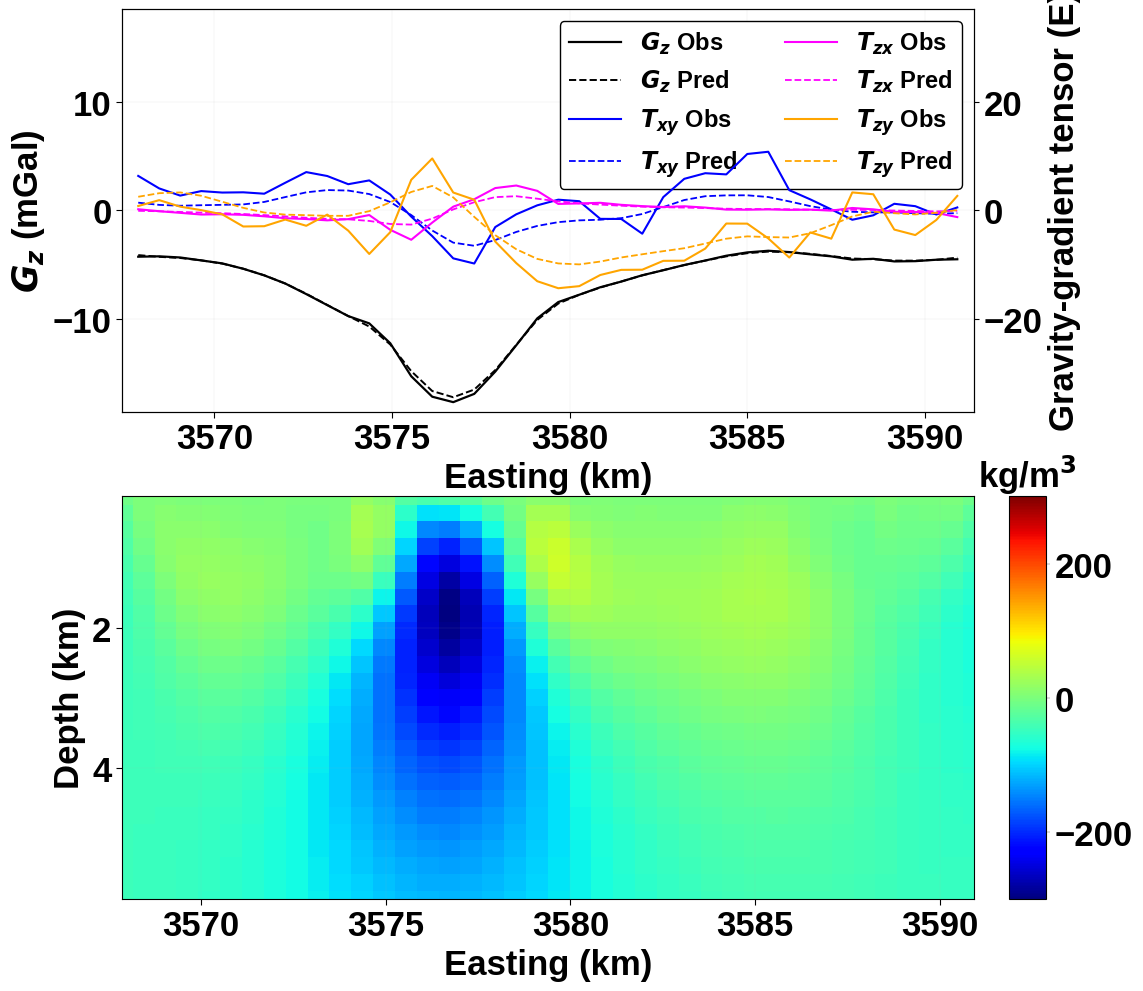

Saved: Fig16_All_EW_Profiles_Gz_Density_Section.png


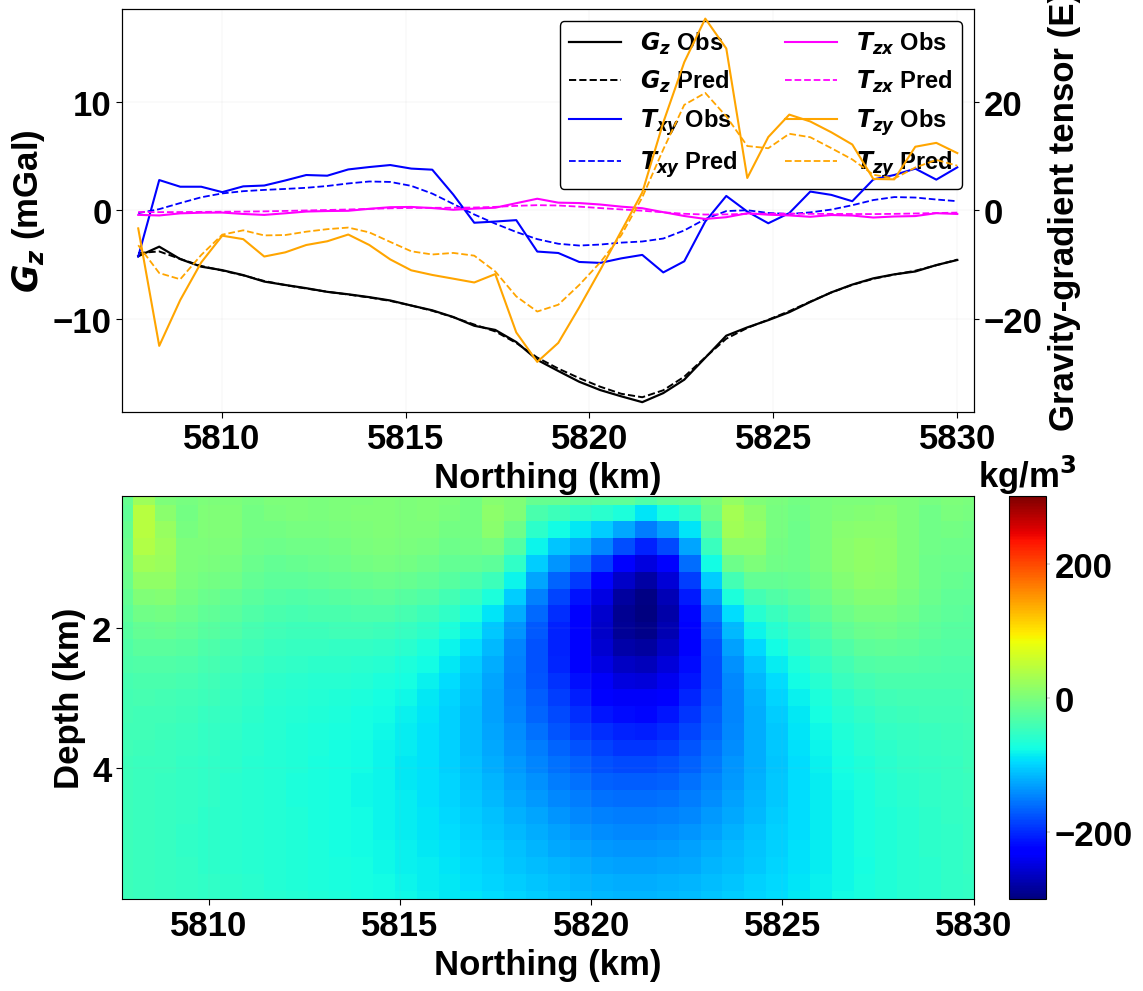

Saved: Fig17_All_NS_Profiles_Gz_Density_Section.png


In [4]:
# =====================================================================
# 17–18. REAL-DATA EW/NS PROFILES + Gz DENSITY SECTIONS
# Top: Gz + Txy + Tzx + Tzy | Bottom: Gz density section
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl
import glob

mpl.rcParams["font.family"]="Liberation Sans"
# =====================================================================
# FONT SETTINGS
# =====================================================================
X_LABEL_SIZE=Y_LABEL_SIZE=25
TICK_LABEL_SIZE_TOP=TICK_LABEL_SIZE_BOTTOM=TICK_LABEL_SIZE_RIGHT=25
COLORBAR_TICK_SIZE=RIGHT_Y_LABEL_SIZE=COLORBAR_LABEL_SIZE=25
LEGEND_SIZE=17
# =====================================================================
# COMPONENTS AND COLOURS
# =====================================================================
components={
    "Gz":("Gz_Gravity",r"G_z","mGal"),
    "Txy":("txy_Tensor",r"T_{xy}","E"),
    "Tzx":("tzx_Tensor",r"T_{zx}","E"),
    "Tzy":("tzy_Tensor",r"T_{zy}","E")
}
comp_colors={"Txy":"blue","Tzx":"magenta","Tzy":"orange"}

# =====================================================================
# 2-D AXIS STYLE
# =====================================================================
def _style(ax,xl="",yl=""):
    ax.set_facecolor(AX)
    ax.tick_params(colors=TC,labelsize=25,direction="out",width=.8,length=4)
    ax.set_xlabel(xl,color=TC,fontsize=X_LABEL_SIZE)
    ax.set_ylabel(yl,color=TC,fontsize=Y_LABEL_SIZE)
    for s in ax.spines.values():
        s.set_edgecolor(TC);s.set_linewidth(.8)

# =====================================================================
# READ ALL REAL-DATA EXCEL PROFILES
# =====================================================================
def read_profiles(direction):
    data={}
    for comp,(name,label,unit) in components.items():
        files=glob.glob(f"{direction}_{name}_Profile_*.xlsx")
        if not files:
            raise FileNotFoundError(f"No {direction} {comp} profile Excel file found.")
        df=pd.read_excel(files[0])
        data[comp]={
            "coord":df.iloc[:,0].to_numpy(),
            "obs":df.iloc[:,1].to_numpy(),
            "pred":df.iloc[:,2].to_numpy(),
            "label":label,"unit":unit
        }
    return data

# =====================================================================
# COMMON Y-AXIS LIMITS
# =====================================================================
def get_common_limits(ew,ns):
    gz=np.concatenate([ew["Gz"]["obs"],ew["Gz"]["pred"],
                       ns["Gz"]["obs"],ns["Gz"]["pred"]])
    tensor=np.concatenate([
        np.r_[d[c]["obs"],d[c]["pred"]]
        for c in ["Txy","Tzx","Tzy"] for d in [ew,ns]
    ])
    return ((-1.05*np.nanmax(np.abs(gz)),1.05*np.nanmax(np.abs(gz))),
            (-1.05*np.nanmax(np.abs(tensor)),1.05*np.nanmax(np.abs(tensor))))

# =====================================================================
# PLOT ALL PROFILES + Gz DENSITY SECTION
# =====================================================================
def plot_profiles_density(direction,data,gz_ylim,tensor_ylim,filename):

    # Model-cell centres: local m → absolute km
    xc,yc,zc=[(a[:-1]+a[1:])/2 for a in (xe,ye,ze)]
    xc_km,yc_km,zc_km=xc/1000+x0,yc/1000+y0,zc/1000

    # Select density section directly from inverted model mp3
    if direction=="EW":
        section=mp3[:,iy_min,:]
        Xsec,Zsec=np.meshgrid(xe_c_p/1000+x0,zc_km)
        xlabel="Easting (km)"
    else:
        section=mp3[:,:,ix_min]
        Xsec,Zsec=np.meshgrid(ye_c_p/1000+y0,zc_km)
        xlabel="Northing (km)"

    # Figure layout
    fig=plt.figure(figsize=(11,10))
    gs=fig.add_gridspec(2,2,height_ratios=[1,1],
                        width_ratios=[1,.043],hspace=.21,wspace=.08)
    ax1=fig.add_subplot(gs[0,0]); ax2=fig.add_subplot(gs[1,0])
    cax=fig.add_subplot(gs[1,1]); fig.patch.set_facecolor(BG)

    # Gz profile
    v=data["Gz"]
    ax1.plot(v["coord"],v["obs"],"k-",lw=1.6,label=r"$G_z$ Obs")
    ax1.plot(v["coord"],v["pred"],"k--",lw=1.4,label=r"$G_z$ Pred")
    xmin,xmax=np.nanmin(v["coord"]),np.nanmax(v["coord"])
    margin=.02*(xmax-xmin)
    ax1.set_xlim(xmin-margin,xmax+margin); ax1.set_ylim(*gz_ylim)
    _style(ax1,xlabel,r"$G_z$ (mGal)")
    ax1.tick_params(labelsize=TICK_LABEL_SIZE_TOP); ax1.grid(True,lw=.35,alpha=.25)

    # Tensor components: right axis
    ax1r=ax1.twinx()
    for comp in ["Txy","Tzx","Tzy"]:
        v,c=data[comp],comp_colors[comp]
        ax1r.plot(v["coord"],v["obs"],color=c,lw=1.5,label=rf"${v['label']}$ Obs")
        ax1r.plot(v["coord"],v["pred"],color=c,lw=1.3,ls="--",label=rf"${v['label']}$ Pred")
    ax1r.set_ylim(*tensor_ylim)
    ax1r.set_ylabel("Gravity-gradient tensor (E)",fontsize=RIGHT_Y_LABEL_SIZE,color=TC)
    ax1r.tick_params(axis="y",labelsize=TICK_LABEL_SIZE_RIGHT,colors=TC)
    ax1r.spines["right"].set_color(TC)

    # Combined legend
    h1,l1=ax1.get_legend_handles_labels(); h2,l2=ax1r.get_legend_handles_labels()
    ax1.legend(h1+h2,l1+l2,loc="upper right",fontsize=LEGEND_SIZE,ncol=2,
               frameon=True,framealpha=1,edgecolor="black",borderpad=.4,handlelength=2.2)

    # Gz density section: directly from mp3, no Excel file required
    pcm=ax2.pcolormesh(Xsec,Zsec,section,cmap=cmap_m,
                       vmin=clim[0],vmax=clim[1],shading="auto")
    ax2.set(xlim=(Xsec.min(),Xsec.max()),ylim=(zc_km.max(),zc_km.min()))
    _style(ax2,xlabel,"Depth (km)")
    ax2.tick_params(labelsize=TICK_LABEL_SIZE_BOTTOM); ax2.grid(True,lw=.35,alpha=.20)

    # Density colourbar
    cb=fig.colorbar(pcm,cax=cax)
    cax.set_title(r"kg/m$^3$",color=TC,fontsize=COLORBAR_LABEL_SIZE,
                  fontweight="bold",pad=6)
    cb.ax.tick_params(labelsize=COLORBAR_TICK_SIZE,colors=TC,
                      direction="out",width=.2,length=3)
    plt.setp(cb.ax.get_yticklabels(),fontweight="bold")
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)

    # Save
    fig.subplots_adjust(left=.09,right=.93,top=.96,bottom=.07)
    fig.savefig(filename,dpi=600,bbox_inches="tight",pad_inches=.02,facecolor=BG)
    plt.show(); plt.close(fig)
    print("Saved:",filename)

# =====================================================================
# READ PROFILES AND COMMON LIMITS
# =====================================================================
ew_data=read_profiles("EW")
ns_data=read_profiles("NS")
gz_ylim,tensor_ylim=get_common_limits(ew_data,ns_data)

# =====================================================================
# FIGURES 16–17
# =====================================================================
plot_profiles_density("EW",ew_data,gz_ylim,tensor_ylim,
                      "Fig16_All_EW_Profiles_Gz_Density_Section.png")

plot_profiles_density("NS",ns_data,gz_ylim,tensor_ylim,
                      "Fig17_All_NS_Profiles_Gz_Density_Section.png")



EW Density section along maximum negative density contrast at y(Northing) = 5821.44 km
NS Density section along maximum negative density contrast at x(Easting) = 3576.72 km


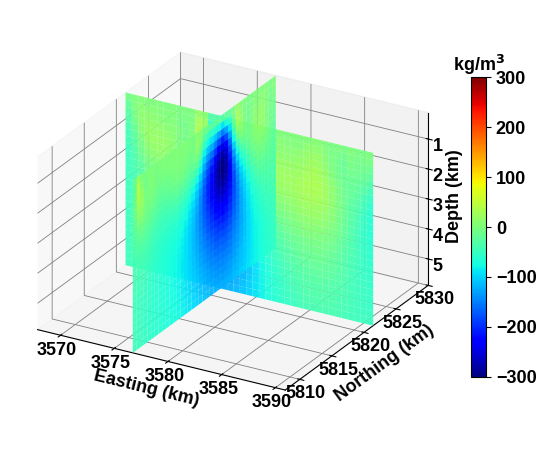

Saved: EW_NS_density_sections_3D_combined.png


In [14]:
# ---------------------------------------------------------------------
# 10. COMBINED 3-D EW/NS SECTIONS
# ---------------------------------------------------------------------
def plot_3d_sections_combined(rho_ew, X_ew, Y_ew, Z_ew,
                              rho_ns, X_ns, Y_ns, Z_ns, filename):

    # Create common 3-D figure
    fig=plt.figure(figsize=(7,6))
    ax=fig.add_subplot(111,projection="3d")

    # EW section
    fc=cmap_m(norm_m(rho_ew)); fc[...,3]=.95
    ax.plot_surface(X_ew,Y_ew,Z_ew,facecolors=fc,rstride=1,cstride=1,
                    linewidth=0,edgecolor="none",shade=False)

    # NS section
    fc=cmap_m(norm_m(rho_ns)); fc[...,3]=.95
    ax.plot_surface(X_ns,Y_ns,Z_ns,facecolors=fc,rstride=1,cstride=1,
                    linewidth=0,edgecolor="none",shade=False)

    # Axis labels
    ax.set_xlabel("Easting (km)",fontsize=FS,fontweight="bold",labelpad=-4.0)
    ax.set_ylabel("Northing (km)",fontsize=FS,fontweight="bold",labelpad=-3.0)
    ax.set_zlabel("Depth (km)",fontsize=FS,fontweight="bold",labelpad=-10.0)

    # Axis limits
    ax.set_xlim(x.min()+x0,x.max()+x0)
    ax.set_ylim(y.min()+y0,y.max()+y0)
    ax.set_zlim(z.max(),z.min())

    # Ticks
    ax.set_xticks(np.arange(np.ceil(x.min()+x0/5)*5,x.max()+x0+1,5))
    ax.set_yticks(np.arange(np.ceil(y.min()+y0/5)*5,y.max()+y0+1,5))
    ax.set_zticks(np.arange(np.ceil(z.min()),np.floor(z.max())+1,1))

    # Tick style
    for a in "xyz":
        ax.tick_params(axis=a,colors=TC,labelsize=FS,direction="out",
                       width=.7,length=4,pad=-4.0)
    for t in ax.get_xticklabels()+ax.get_yticklabels()+ax.get_zticklabels():
        t.set_fontweight("bold")

    # Grid
    ax.grid(True)
    for a in (ax.xaxis,ax.yaxis,ax.zaxis):
        a._axinfo["grid"].update(linewidth=.6,linestyle="-",
                                 color="gray",alpha=.5)
    # Same aspect ratio and camera
    ax.set_box_aspect((1.5,1.5,1))
    ax.set_proj_type("ortho")
    ax.view_init(elev=25,azim=-60)

    # Common density colourbar
    sm=mpl.cm.ScalarMappable(cmap=cmap_m,norm=norm_m)
    sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=.65,pad=.05)
    cb.ax.set_title(r"kg/m$^3$",fontsize=FS,fontweight="bold",
                    color=TC,pad=4)
    cb.ax.tick_params(labelsize=FS,colors=TC)

    # Save
    save_fig(fig,filename)
# ---------------------------------------------------------------------
# EW SECTION
# ---------------------------------------------------------------------
rho_ew=mp3[:,iy_min,:]
X_ew,Z_ew=np.meshgrid(x+x0,z)
Y_ew=np.full_like(X_ew,y[iy_min]+y0)

print(f"\n\nEW Density section along maximum negative density contrast "
      f"at y(Northing) = {(ye_c_p[iy_min]/1000+y0):.2f} km")
# ---------------------------------------------------------------------
# NS SECTION
# ---------------------------------------------------------------------
rho_ns=mp3[:,:,ix_min]
Y_ns,Z_ns=np.meshgrid(y+y0,z)
X_ns=np.full_like(Y_ns,x[ix_min]+x0)

print(f"NS Density section along maximum negative density contrast "
      f"at x(Easting) = {(xe_c_p[ix_min]/1000+x0):.2f} km")
# ---------------------------------------------------------------------
# PLOT BOTH SECTIONS ON ONE 3-D AXIS
# ---------------------------------------------------------------------
plot_3d_sections_combined(
    rho_ew,X_ew,Y_ew,Z_ew,
    rho_ns,X_ns,Y_ns,Z_ns,
    "EW_NS_density_sections_3D_combined.png"
)